In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import PIL

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1


In [ ]:
!pip install tensorflow

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive/BrainTumor'))

['Dataset']


In [ ]:
TRAIN_DIR = "/content/drive/MyDrive/BrainTumor/Dataset/Training"
TEST_DIR = "/content/drive/MyDrive/BrainTumor/Dataset/Testing"

In [ ]:
print("Training folders:")
print(os.listdir(TRAIN_DIR))

print("\nTesting folders:")
print(os.listdir(TEST_DIR))

Training folders:
['notumor', 'pituitary', 'glioma', 'meningioma']

Testing folders:
['pituitary', 'notumor', 'meningioma', 'glioma']


In [ ]:
for folder in os.listdir(TRAIN_DIR):
    folder_path = os.path.join(TRAIN_DIR, folder)
    print(folder, ":", len(os.listdir(folder_path)))

notumor : 1400
pituitary : 1400
glioma : 1400
meningioma : 1401


In [ ]:
for folder in os.listdir(TEST_DIR):
    folder_path = os.path.join(TEST_DIR, folder)
    print(folder, ":", len(os.listdir(folder_path)))

pituitary : 400
notumor : 400
meningioma : 400
glioma : 400


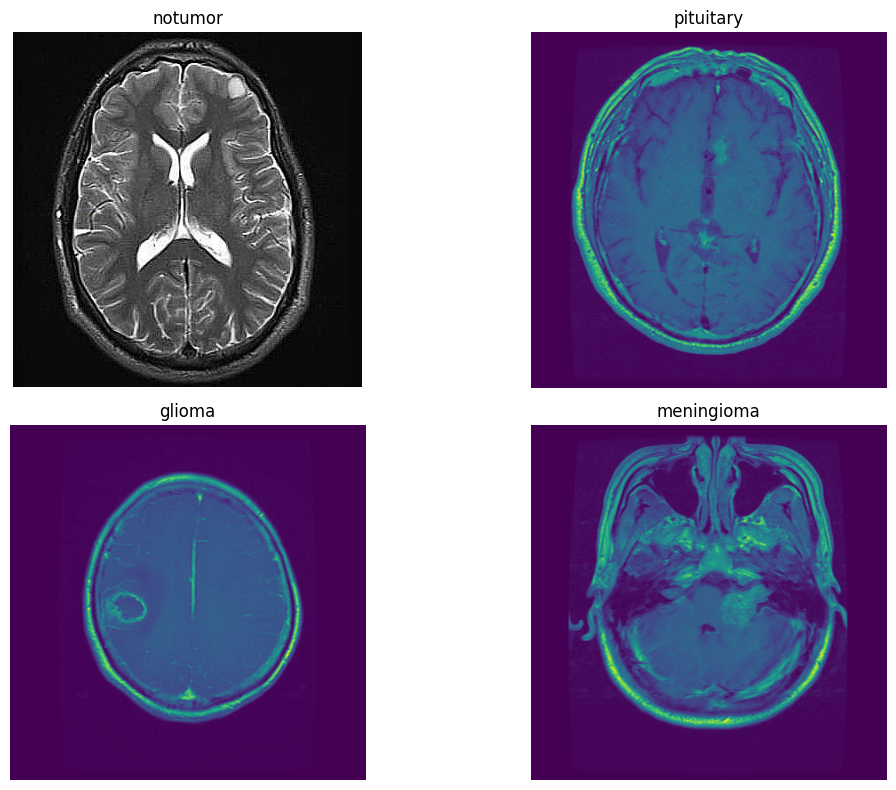

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

classes = os.listdir(TRAIN_DIR)

plt.figure(figsize=(12, 8))

for i, class_name in enumerate(classes):

    class_path = os.path.join(
        TRAIN_DIR,
        class_name
    )

    image_name = os.listdir(class_path)[0]

    image_path = os.path.join(
        class_path,
        image_name
    )

    image = Image.open(image_path)

    plt.subplot(2, 2, i + 1)

    plt.imshow(image)

    plt.title(class_name)

    plt.axis("off")

plt.tight_layout()

plt.show()

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = 128
BATCH_SIZE = 32


In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

In [ ]:
test_datagen = ImageDataGenerator(
    rescale=1.0 / 255
)

In [ ]:
train_data = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True
)

Found 5601 images belonging to 4 classes.


In [ ]:
test_data = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 1600 images belonging to 4 classes.


In [ ]:
print(train_data.class_indices)

{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [ ]:
from tensorflow.keras import models, layers

model = models.Sequential([

    layers.Input(
        shape=(128, 128, 3)
    ),

    # Block 1
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Block 2
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Block 3
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Flatten
    layers.Flatten(),

    # Fully connected
    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.5),

    # 4-class output
    layers.Dense(
        4,
        activation="softmax"
    )
])

In [ ]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,156 (12.61 MB)

 Trainable params: 3,305,156 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    train_data,
    epochs=15,
    validation_data=test_data
)

Epoch 1/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 53s 303ms/step - accuracy: 0.9605 - loss: 0.1085 - val_accuracy: 0.9175 - val_loss: 0.8211
Epoch 2/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 48s 272ms/step - accuracy: 0.9498 - loss: 0.1259 - val_accuracy: 0.9075 - val_loss: 0.7216
Epoch 3/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 49s 281ms/step - accuracy: 0.9654 - loss: 0.0963 - val_accuracy: 0.9075 - val_loss: 0.8590
Epoch 4/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 47s 269ms/step - accuracy: 0.9646 - loss: 0.0968 - val_accuracy: 0.9144 - val_loss: 0.9089
Epoch 5/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 48s 271ms/step - accuracy: 0.9718 - loss: 0.0832 - val_accuracy: 0.9200 - val_loss: 0.9034
Epoch 6/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 51s 291ms/step - accuracy: 0.9707 - loss: 0.0801 - val_accuracy: 0.9350 - val_loss: 0.8535
Epoch 7/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 49s 279ms/step - accuracy: 0.9684 - loss: 0.0736 - val_accuracy: 0.9225 - val_loss: 0.9510
Epoch 8/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 49s 281ms/step - accuracy: 0.9713 - loss: 0

In [ ]:
MODEL_PATH = "/content/drive/MyDrive/BrainTumor/brain_tumor_model.keras"

model.save(MODEL_PATH)

print("Model saved successfully!")
print(MODEL_PATH)

Model saved successfully!
/content/drive/MyDrive/BrainTumor/brain_tumor_model.keras


In [ ]:
import tensorflow as tf

MODEL_PATH = "/content/drive/MyDrive/BrainTumor/brain_tumor_model.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
class_names = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

In [ ]:
print(class_names)

['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving brain.jpg to brain.jpg


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 805ms/step
Predicted Class: meningioma
Confidence: 58.97%


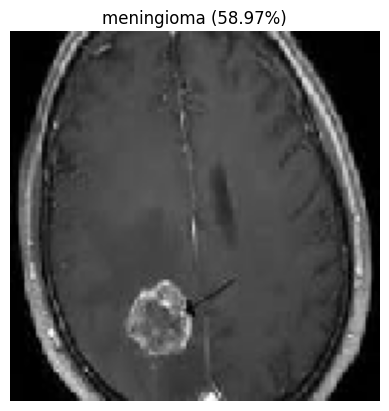

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

# Get uploaded file name
img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(
    img_path,
    target_size=(128, 128)
)

# Convert image to array
img_array = image.img_to_array(img)

# Normalize pixel values
img_array = img_array / 255.0

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Make prediction
prediction = model.predict(img_array)

# Get predicted class
predicted_index = np.argmax(prediction[0])
predicted_class = class_names[predicted_index]

# Get confidence
confidence = prediction[0][predicted_index] * 100

print("Predicted Class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

# Display image
plt.imshow(img)
plt.axis("off")
plt.title(f"{predicted_class} ({confidence:.2f}%)")
plt.show()

In [ ]:
for i, class_name in enumerate(class_names):
    print(f"{class_name}: {prediction[0][i] * 100:.2f}%")

glioma: 0.44%
meningioma: 58.97%
notumor: 5.33%
pituitary: 35.26%
